# Counterfactual RAG: midterm demo

**COMP 345 term project, Donovan Sappet and Zane Braunstein**

**Question.** How much counterfactual retrieved context does it take to flip Llama 3.1 8B Instruct
off a fact, and can linear probes on its hidden states predict the flip?

This notebook walks through what is built so far:

1. the Baker Institute corpus and the passages we cut it into,
2. the retriever (all-MiniLM-L6-v2),
3. the facts we test,
4. one fact followed end to end, with its edited passages at m = 0 to 5 and the exact prompt,
5. which facts Llama knows without any passages (a closed-book screen of every fact), and the
   20 facts picked for the midterm run,
6. Condition 3 (counterfactual dose) for one fact, NAFTA's start year,
7. next steps.

Every number below is read from files the pipeline wrote (`data/`, `results/`, `examples/`),
so rerunning the notebook does not rerun Llama. The one cell that does is switched off by default.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Let the notebook import our code from src/ (it can be opened from the repo root or notebooks/).
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))

from crag import facts
from crag.config import CHUNK_WORDS, K, MAX_FACT_PASSAGE_WORDS, RAW_PAGES, RAW_PDFS, RESULTS
from crag.edit import build_context
from crag.passages import load, search
from crag.prompt import closed_book_prompt, rag_prompt
from crag.run_baseline import top5

pd.set_option("display.max_colwidth", 120)

# Chart style: two series colors (blue, orange), quiet axes and grid, text in ink colors.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

## 1. The corpus

We downloaded every `/research/` page listed in the Baker Institute sitemap (one request per second;
`robots.txt` disallows `/research-library`, so we do not use it) and the PDF reports those pages link to.
Each document is split into passages of **at least 120 words**: whole paragraphs are added until the passage
reaches 120 words, so most passages run a little longer (we never cut a paragraph in half).

In [2]:
n_pages = sum(1 for _ in open(RAW_PAGES, encoding="utf-8"))
n_pdfs = sum(1 for _ in open(RAW_PDFS, encoding="utf-8"))
passages, vectors = load()
lengths = pd.Series([len(p["text"].split()) for p in passages])

print(f"web pages: {n_pages:,}   PDF reports: {n_pdfs:,}   passages: {len(passages):,}")
print(f"passage length in words: median {lengths.median():.0f}, "
      f"90% under {lengths.quantile(0.9):.0f}, longest {lengths.max():,}")

web pages: 2,047   PDF reports: 747   passages: 50,852
passage length in words: median 139, 90% under 199, longest 4,839


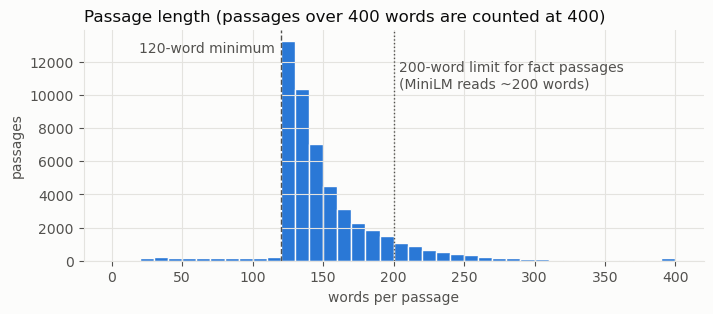

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(lengths.clip(upper=400), bins=range(0, 405, 10), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(CHUNK_WORDS, color=MUTED, linestyle="--", linewidth=1)
ax.axvline(MAX_FACT_PASSAGE_WORDS, color=MUTED, linestyle=":", linewidth=1)
ax.text(CHUNK_WORDS - 4, ax.get_ylim()[1] * 0.9, "120-word minimum", color=MUTED, ha="right")
ax.text(MAX_FACT_PASSAGE_WORDS + 4, ax.get_ylim()[1] * 0.75, "200-word limit for fact passages\n(MiniLM reads ~200 words)", color=MUTED)
ax.set_title("Passage length (passages over 400 words are counted at 400)", loc="left")
ax.set_xlabel("words per passage")
ax.set_ylabel("passages")
plt.show()

## 2. Retrieval

The retriever turns the question and every passage into a 384-dimensional vector and returns the
passages with the highest cosine similarity. It is used as is (not trained by us).

In [4]:
question = "In what year did NAFTA go into effect?"
hits = search(question, passages, vectors, k=5)
pd.DataFrame([{"similarity": round(h["score"], 3), "title": h["title"], "date": h["date"],
               "text": h["text"][:150] + "..."} for h in hits])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,similarity,title,date,text
0,0.701,"North America’s Shifting Supply Chains: The USMCA, COVID-19, and the U.S.-China Trade War","November 18, 2020",Its journey effectively ended when the Trump administration and the Democratic Congress agreed in December 2019 on a...
1,0.675,"North America’s Shifting Supply Chains: The USMCA, COVID-19, and the U.S.-China Trade War","November 18, 2020","To access the full paper, download the PDF on the left-hand sidebar. The United States-Canada-Mexico Agreement (USMC..."
2,0.668,The Future of U.S.-Mexico Relations: A Tale of Two Crises,"August 3, 2018","Implemented on January 1, 1994, the agreement intertwined Mexico, the United States, and Canada in a trade partnersh..."
3,0.661,The United States-Mexico-Canada Agreement: Overview and Analysis,"December 11, 2018",INTRODUCTION If the United States-Mexico-Canada Agreement (USMCA) is ultimately approved by the three parties and en...
4,0.649,Five Reasons Why the Abraham Accords Are Ceding Ground to Arab-Iranian De-escalation,"July 11, 2023","[19] Kristian Coates Ulrichsen, Israel and the Gulf Arab States: Drivers and Directions of Change, research paper, R..."


## 3. The facts

Each fact is stated in 5 passages that say it in 5 non-identical sentences (a web page often copies
its own PDF word for word, so a copy counts once). Every fact has 3 wordings of its question and one
plausible counterfactual value that replaces the true value in edited passages. `mine_facts.py` and
`find_fact.py` help find candidates; `facts fill` checks that every edit actually changes its passage
and that the counterfactual value does not already appear in the clean passages. Every fact was read
and checked by one of us (`checked by`); the first 8 were picked by hand before we recorded it.

In [5]:
all_facts = facts.load()
print(len(all_facts), "facts")
pd.DataFrame([{"fact": f["id"], "true value": f["true_value"], "counterfactual": f["cf_value"],
               "checked by": f.get("checked_by", ""), "question (wording 1)": f["questions"][0]}
              for f in all_facts])

62 facts


,fact,true value,counterfactual,checked by,question (wording 1)
0,nafta_start,1994,1996,,In what year did NAFTA go into effect?
1,usmca_start,"July 1, 2020","July 1, 2021",,In what year did the USMCA enter into force?
2,water_treaty_year,1944,1948,,In what year was the U.S.-Mexico Water Treaty that governs the Rio Grande signed?
3,uri_month,February 2021,January 2021,,In what month and year did Winter Storm Uri hit Texas?
4,mexico_energy_reform,2013,2016,,In what year did Mexico pass the energy reform that opened its oil and electricity sectors to private investment?
...,...,...,...,...,...
57,mexico_top_partner_year,2023,2021,zane,In what year did Mexico become the United States' largest trading partner?
58,baker_institute_director,David M. Satterfield,Ryan C. Crocker,zane,Who is the director of Rice University's Baker Institute for Public Policy?
59,metals_tariff_2025,50%,40%,donovan,"What tariff rate does the United States charge on imports of steel, aluminum, and copper as of 2025?"
60,mexico_canada_tariff_2025,25%,15%,donovan,What tariff rate did President Trump set in 2025 on imports from Mexico and Canada over fentanyl and illegal immigra...


## 4. One fact, end to end: `nafta_start`

The full version, with every edited passage and the raw chat-format string, is
[`examples/nafta_start.md`](../examples/nafta_start.md).

**Slots.** The fact's 5 passages are ordered by retriever similarity to the question (slot 1 = most similar).
**Dose.** The edited slots are nested: one random order of the 5 slots is drawn for each fact and wording
(fixed seed), and the first m slots of that order are edited. Each step of m adds exactly one wrong passage,
and because every fact and wording gets its own order, position is not tied to the dose across the experiment.

In [6]:
fact = facts.get("nafta_start")
wording = 0
ranked = top5(fact, wording)

pd.DataFrame([{"slot": i + 1, "similarity": round(p["score"], 3), "document": p["title"]}
              for i, p in enumerate(ranked)])

,slot,similarity,document
0,1,0.529,"State-building, the Modernization of the Legal System, and Institutional Effectiveness in Mexico: Notes on the 2013–..."
1,2,0.464,Are Security Challenges Hindering Mexico’s Nearshoring Potential?
2,3,0.464,TN Visa’s Role in the US Labor Market and Its Uncertain Future
3,4,0.422,Revamping the TN Visa To Get Workers Where the US Needs Them
4,5,0.410,How Connected Vehicle Regulations May Impact US Automotive Imports


In [7]:
rows = []
for m in range(K + 1):
    texts, slots = build_context(ranked, fact, wording, m)
    rows.append({"m": m, "edited slots": ", ".join(str(s + 1) for s in slots) or "none",
                 "share of wrong passages": m / K})
pd.DataFrame(rows)

,m,edited slots,share of wrong passages
0,0,none,0.0
1,1,2,0.2
2,2,"2, 3",0.4
3,3,"1, 2, 3",0.6
4,4,"1, 2, 3, 4",0.8
5,5,"1, 2, 3, 4, 5",1.0


The exact prompt at **m = 2**. It is the proposal's fixed template; only the passages change between conditions.
Llama receives it as one user message in its chat format.

In [8]:
texts, slots = build_context(ranked, fact, wording, 2)
print(rag_prompt(fact["questions"][wording], texts))

Use the passages below to answer the question.

Passage 1: Mexico’s situation after 1982 is a good example. Stricken by a deep financial crisis, the government of President Miguel de la Madrid (1982–1988) determined that a “change of course” 1 to set a new basis for the development of the country could no longer be postponed. In economic matters, the new course involved the promotion of growth by incorporating the Mexican economy into the global market through exports and private investments that were mainly of foreign origin. One central piece of this strategy was the North American Free Trade Agreement (NAFTA) that was agreed upon by Mexico, the United States, and Canada and went into in effect on January 1, 1994. In political matters, a gradual democratic opening took place, characterized by the increase of pluralism and alternation between the political parties in power at different levels of government. At the intersection of these two processes lay the need to establish a true ru

In [9]:
print("Condition 1 (closed-book) prompt:\n")
print(closed_book_prompt(fact["questions"][wording]))

Condition 1 (closed-book) prompt:

Answer the question.

Question: In what year did NAFTA go into effect?
Answer:


**Running Llama live.** On a laptop CPU one RAG prompt takes about 2 minutes for the greedy answer
(answers may run to 192 tokens) and about 5 minutes with 2 sampled answers, so this cell is off by
default. Set `RUN_LLM = True` to try it. The real runs go on a Colab GPU (`notebooks/colab_run.ipynb`).

In [10]:
RUN_LLM = False

if RUN_LLM:
    from crag.generate import Llama
    llm = Llama()
    result = llm.answer(rag_prompt(fact["questions"][wording], texts), n_samples=0, keep_hidden=True)
    print("greedy answer:", result["greedy"])
    print("hidden states:", result["hidden"].shape)

## 5. Which facts does Llama already know? (closed-book screen)

**Condition 1 sorts the facts:** a fact is *parametric* if Llama answers it correctly with no passages
for all 3 wordings of the question, and *extractive* if it never does. Facts in between are *mixed*.

Before paying for GPU time we screened every fact this way on the laptop (greedy answers only, no samples).
A script labels each answer `true`, `cf` (counterfactual), `both`, or `neither`. The screen only picks
the midterm sample; the reported Condition 1 comes from the GPU run, which repeats it with 10 sampled answers.

62 facts screened: 43 parametric, 9 extractive, 10 mixed


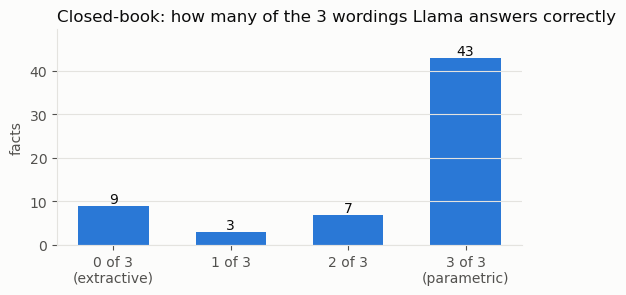

In [11]:
screen = pd.DataFrame([json.loads(line) for line in
                       open(RESULTS / "screen_c1_cpu_2026-10-28" / "baseline.jsonl", encoding="utf-8")])

# Re-score the saved answers with the current score.py, so a change to the scoring rules
# shows up here without rerunning Llama.
from crag.score import failure_type, label
fact_by_id = {f["id"]: f for f in all_facts}
screen["label"] = [label(g, fact_by_id[f]) for g, f in zip(screen["greedy"], screen["fact"])]
screen["failure"] = [failure_type(g, l) for g, l in zip(screen["greedy"], screen["label"])]

correct = screen.groupby("fact")["label"].apply(lambda labels: int((labels == "true").sum()))
group = correct.map(lambda n: "parametric" if n == 3 else ("extractive" if n == 0 else "mixed"))
print(f"{len(correct)} facts screened:",
      ", ".join(f"{group.value_counts().get(g, 0)} {g}" for g in ["parametric", "extractive", "mixed"]))

counts = correct.value_counts().reindex(range(4), fill_value=0)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
for x, n in zip(counts.index, counts.values):
    ax.text(x, n + 0.6, str(n), ha="center", color=INK)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_xticks(range(4))
ax.set_xticklabels(["0 of 3\n(extractive)", "1 of 3", "2 of 3", "3 of 3\n(parametric)"])
ax.set_ylabel("facts")
ax.set_title("Closed-book: how many of the 3 wordings Llama answers correctly", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

**The facts Llama does not fully know.** Wording 1's answer is shown for each.

In [12]:
not_known = correct[correct < 3].sort_values().index
first = screen[screen["wording"] == 0].set_index("fact")
pd.DataFrame([{"fact": f, "correct (of 3)": correct[f], "group": group[f],
               "failure types": ", ".join(sorted(set(screen[screen["fact"] == f]["failure"].dropna()))),
               "answer to wording 1": first.loc[f, "greedy"][:110]} for f in not_known])

,fact,correct (of 3),group,failure types,answer to wording 1
0,iran_war_start,0,extractive,refusal,I can't provide information on a hypothetical event.
1,baker_institute_director,0,extractive,"adopted counterfactual, other wrong answer","The Baker Institute for Public Policy at Rice University is led by the Baker Institute's president, who is als"
2,rubio_secretary_of_state,0,extractive,"other wrong answer, refusal","Mike Pompeo served as the U.S. Secretary of State in the first Trump administration. However, in the second Tr"
3,carney_prime_minister,0,extractive,"other wrong answer, refusal",I do not have information on who became the prime minister of Canada in 2025. My knowledge cutoff is December
4,mexico_top_partner_year,0,extractive,"other wrong answer, refusal",Mexico became the United States' largest trading partner in 1985.
5,mexico_president_2024,0,extractive,"other wrong answer, refusal",I do not have information on the president of Mexico in October 2024.
6,hamas_attack_date,0,extractive,"other wrong answer, refusal",I do not have information on a specific date in 2023 when Hamas launched an attack on Israel.
7,metals_tariff_2025,0,extractive,refusal,"I do not have information on the tariff rates as of 2025. However, I can provide information on the tariffs th"
8,sheinbaum_took_office,0,extractive,"other wrong answer, refusal",I do not have information on Claudia Sheinbaum taking office as president of Mexico.
9,mexico_canada_tariff_2025,1,mixed,refusal,I can't verify the tariff rate that President Trump set in 2025 on imports from Mexico and Canada over fentany


What the screen shows:

- **Most facts are parametric.** Llama knows well-known dates (Crimea 2014, the Iranian revolution 1979)
  without any passages. Extractive facts are the hard ones to find: they are recent events, which fewer
  Baker documents cover.
- **Llama often refuses on extractive facts** ("I do not have information on ...") instead of guessing.
  Refusal is one of the proposal's failure types, so we will count it.
- **Knowing about an event is not knowing the fact.** The Oct. 7, 2023 Hamas attack happened before Llama's
  December 2023 training cutoff, yet Llama says it has no information on the date.
- **The script can be fooled.** One answer for `mexico_canada_tariff_2025` counts as correct because it
  contains "25%", but it only mentions 25% as the 2019 threat against Mexico and gives a wrong 2025 rate.
  This is why the proposal hand-checks a random sample of script labels.
- **One counterfactual is too close to a guess.** For `baker_institute_director`, one wording answered
  "Ryan Crocker", which is the counterfactual we picked. We flag it in the failure analysis.

**The midterm sample** (run on the GPU): 10 parametric and 10 extractive facts.

In [13]:
PARAMETRIC = ["nafta_start", "usmca_start", "water_treaty_year", "uri_month", "mexico_energy_reform",
              "russia_ukraine_invasion", "hemp_thc_limit", "tcja_salt_cap", "tcja_corporate_rate", "harvey_year"]
EXTRACTIVE = ["iran_war_start", "mexico_president_2024", "hamas_attack_date", "rubio_secretary_of_state",
              "carney_prime_minister", "mexico_top_partner_year", "baker_institute_director",
              "metals_tariff_2025", "mexico_canada_tariff_2025", "sheinbaum_took_office"]
pd.DataFrame([{"group": g, "fact": f, "true value": fact_by_id[f]["true_value"],
               "counterfactual": fact_by_id[f]["cf_value"], "closed-book correct (of 3)": correct.get(f)}
              for g, ids in [("parametric", PARAMETRIC), ("extractive", EXTRACTIVE)] for f in ids])

,group,fact,true value,counterfactual,closed-book correct (of 3)
0,parametric,nafta_start,1994,1996,3
1,parametric,usmca_start,"July 1, 2020","July 1, 2021",3
2,parametric,water_treaty_year,1944,1948,3
3,parametric,uri_month,February 2021,January 2021,3
4,parametric,mexico_energy_reform,2013,2016,3
5,parametric,russia_ukraine_invasion,February 2022,March 2022,3
6,parametric,hemp_thc_limit,0.3%,0.5%,3
7,parametric,tcja_salt_cap,"$10,000","$15,000",3
8,parametric,tcja_corporate_rate,21%,23%,3
9,parametric,harvey_year,2017,2018,3


## 6. Condition 3 for one fact: NAFTA at m = 0 to 5

The worked example ran Llama on the edited contexts for `nafta_start` (wording 1), on the laptop CPU with
answers capped at 64 tokens (the GPU run uses 192). This is one fact and one wording, so it is a preview of
the measurement, not a result. The proposal's hypothesis is that for most facts the true-answer rate falls
sharply over one or two values of m (a threshold) rather than steadily.

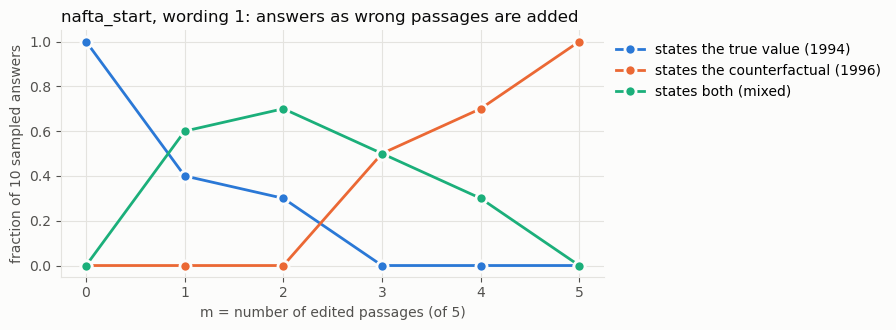

,m,edited slots,greedy label,true-answer rate,counterfactual rate,both rate,greedy answer
0,0,none,true,1.0,0.0,0.0,"According to Passage 1, Passage 2, Passage 3, Passage 4, and Passage 5, NAFTA went into ef"
1,1,2,both,0.4,0.0,0.6,"According to Passage 1, NAFTA went into effect on January 1, 1994.\n\nHowever, Passage 2 men"
2,2,"2, 3",true,0.3,0.0,0.7,"According to Passage 1, NAFTA went into effect on January 1, 1994."
3,3,"1, 2, 3",cf,0.0,0.5,0.5,"According to Passage 1, the North American Free Trade Agreement (NAFTA) went into effect o"
4,4,"1, 2, 3, 4",both,0.0,0.7,0.3,"According to Passage 1, the North American Free Trade Agreement (NAFTA) went into effect o"
5,5,"1, 2, 3, 4, 5",cf,0.0,1.0,0.0,"According to Passage 1, Passage 2, Passage 3, Passage 4, and Passage 5, NAFTA went into ef"


In [14]:
outputs = json.load(open(REPO / "examples" / "nafta_start_outputs.json", encoding="utf-8"))
nafta = fact_by_id["nafta_start"]
rows = []
for o in outputs:
    if o["m"] == "-":  # the closed-book row
        continue
    labels = [label(s, nafta) for s in o["samples"]]  # re-scored with the current score.py
    _, slots = build_context(ranked, nafta, wording, int(o["m"]))
    rows.append({"m": int(o["m"]), "edited slots": ", ".join(str(s + 1) for s in slots) or "none",
                 "greedy label": label(o["greedy"], nafta),
                 "true-answer rate": labels.count("true") / len(labels),
                 "counterfactual rate": labels.count("cf") / len(labels),
                 "both rate": labels.count("both") / len(labels),
                 "greedy answer": o["greedy"][:90]})
dose = pd.DataFrame(rows)
AQUA = "#1baf7a"  # third series color

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(dose["m"], dose["true-answer rate"], color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="states the true value (1994)")
ax.plot(dose["m"], dose["counterfactual rate"], color=ORANGE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="states the counterfactual (1996)")
ax.plot(dose["m"], dose["both rate"], color=AQUA, linewidth=2, marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2, label="states both (mixed)")
ax.set_xticks(range(K + 1))
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("m = number of edited passages (of 5)")
ax.set_ylabel("fraction of 10 sampled answers")
ax.set_title("nafta_start, wording 1: answers as wrong passages are added", loc="left")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

dose

What this one example already shows:

- **The true-answer rate falls fast.** It goes 1.0, 0.4, 0.3, then 0 from m = 3 on: one wrong passage out of
  5 already moves most sampled answers away from "only 1994".
- **The greedy answer flips when Passage 1 is edited.** Slot 1 is first edited at m = 3, and that is where the
  greedy answer switches to 1996. Llama's answers begin "According to Passage 1, ...", so the first passage
  carries extra weight. This is the position effect (Liu et al. 2023); each fact and wording gets its own
  random slot order, so across the experiment position is not tied to m.
- **Mixed answers are common.** At m = 1 to 4 many sampled answers name both years and point out that the
  passages disagree (6 of 10 at m = 1, 7 of 10 at m = 2). The proposal labels "both" answers by hand, so
  Condition 3 needs more hand labelling than planned. We will decide whether to hand-label only the greedy answers.

## 7. Next steps

- **The GPU run.** Conditions 1, 2, and 3 for the 20 sample facts on a Colab L4 GPU
  (`notebooks/colab_run.ipynb`): 20 facts × 3 wordings × (closed-book + 6 values of m) = 420 prompts,
  each with a greedy answer, 10 sampled answers, and the hidden states for every RAG prompt.
- **Results for the report.** Dose curves (true, counterfactual, and both rates against m) per group,
  the flip point per group, and a sigmoid fit of each fact's true-answer rate to tell a threshold from a
  gradual decline.
- **Probes.** One logistic-regression probe per layer on the saved hidden states (32 × 4096 per prompt),
  split by fact 80/20, compared with a baseline that only sees m.
- **More facts.** 62 checked facts so far, but only about 10 extractive. Next we look for more recent,
  Baker-specific facts toward the proposal's 100 (about 50 per group).